In [37]:
pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv(r"C:\Users\neonm\OneDrive\Desktop\ORCA\ML_model\output.csv")

In [9]:
df.shape

(13241043, 14)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13241043 entries, 0 to 13241042
Data columns (total 14 columns):
 #   Column     Dtype  
---  ------     -----  
 0   depth_bin  str    
 1   time       str    
 2   latitude   float64
 3   longitude  float64
 4   thetao     float64
 5   so         float64
 6   uo         float64
 7   vo         float64
 8   chl        float64
 9   sla        float64
 10  u10        float64
 11  v10        float64
 12  number     int64  
 13  expver     int64  
dtypes: float64(10), int64(2), str(2)
memory usage: 1.6 GB


In [12]:
import pandas as pd
import gc

# 1. Filter to the top layer (0-50m) to reduce memory
df_surface = df[df['depth_bin'] == '0-50m'].copy()

# Free up the heavy base DataFrame
del df
gc.collect()

# 2. Inspect missing value counts per column
print("Missing value counts:")
print(df_surface.isnull().sum())

# 3. Check percentage of missing values
print("\nPercentage of missing values:")
print((df_surface.isnull().sum() / len(df_surface)) * 100)

Missing value counts:
depth_bin          0
time               0
latitude           0
longitude          0
thetao       1330971
so           1330971
uo           1330971
vo           1330971
chl          1329510
sla          1516518
u10                0
v10                0
number             0
expver             0
dtype: int64

Percentage of missing values:
depth_bin     0.000000
time          0.000000
latitude      0.000000
longitude     0.000000
thetao       30.155578
so           30.155578
uo           30.155578
vo           30.155578
chl          30.122476
sla          34.359484
u10           0.000000
v10           0.000000
number        0.000000
expver        0.000000
dtype: float64


In [13]:
# Drop API metadata columns
df_surface = df_surface.drop(columns=['number', 'expver'], errors='ignore')

# Drop any row containing NaN in your physical variables (Land points + cloud gaps)
raw_features = ['thetao', 'so', 'uo', 'vo', 'chl', 'sla', 'u10', 'v10']
df_clean = df_surface.dropna(subset=raw_features).copy()

# Ensure timestamp is in datetime format for tracking
df_clean['time'] = pd.to_datetime(df_clean['time'])

print(f"Original 0-50m rows: {len(df_surface):,}")
print(f"Cleaned valid ocean rows: {len(df_clean):,}")
print(f"Dropped rows (Land / Gaps): {len(df_surface) - len(df_clean):,}")

Original 0-50m rows: 4,413,681
Cleaned valid ocean rows: 2,879,631
Dropped rows (Land / Gaps): 1,534,050


In [16]:
df_clean.info() # ham yaha check karre for any leftover Nan values and there are none 
df_clean.shape
#1,534,050 rows were remvoed from this 

<class 'pandas.DataFrame'>
Index: 2879631 entries, 54 to 11035637
Data columns (total 12 columns):
 #   Column     Dtype         
---  ------     -----         
 0   depth_bin  str           
 1   time       datetime64[us]
 2   latitude   float64       
 3   longitude  float64       
 4   thetao     float64       
 5   so         float64       
 6   uo         float64       
 7   vo         float64       
 8   chl        float64       
 9   sla        float64       
 10  u10        float64       
 11  v10        float64       
dtypes: datetime64[us](1), float64(10), str(1)
memory usage: 299.7 MB


(2879631, 12)

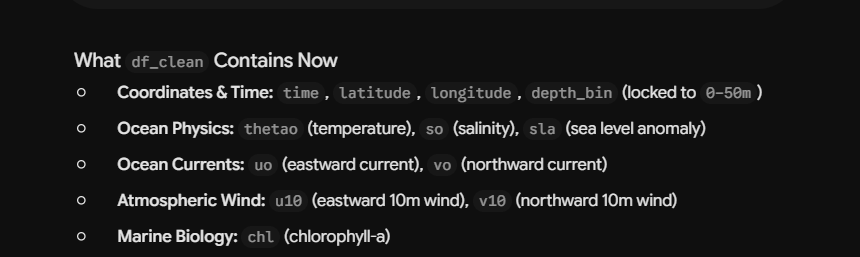

In [19]:
df_clean

,depth_bin,time,latitude,longitude,thetao,so,uo,vo,chl,sla,u10,v10
54,0-50m,2022-01-01,8.25,65.25,28.556505,36.162569,0.481786,0.085248,0.098876,0.059625,-5.245071,-5.131317
55,0-50m,2022-01-01,8.25,65.50,28.545722,36.166214,0.516373,0.042421,0.100664,0.057075,-5.173782,-5.237762
56,0-50m,2022-01-01,8.25,65.75,28.530259,36.183423,0.537804,0.008308,0.102670,0.054450,-5.108353,-5.328583
57,0-50m,2022-01-01,8.25,66.00,28.482976,36.190374,0.543433,-0.000644,0.105666,0.051800,-5.033157,-5.437958
58,0-50m,2022-01-01,8.25,66.25,28.430321,36.193342,0.530683,0.016853,0.110348,0.049350,-5.004837,-5.522919
...,...,...,...,...,...,...,...,...,...,...,...,...
11035621,0-50m,2025-12-31,21.75,68.50,26.154169,35.816692,-0.048151,0.017260,0.224384,0.213625,5.834091,-2.630005
11035622,0-50m,2025-12-31,21.75,68.75,26.013092,35.489381,-0.032078,0.024313,0.265337,0.225400,6.477646,-1.681763
11035623,0-50m,2025-12-31,21.75,69.00,25.772159,34.837557,-0.025500,0.008410,0.304334,0.246025,6.781357,-0.616333
11035624,0-50m,2025-12-31,21.75,69.25,25.297930,33.915983,-0.018398,0.001221,0.322358,0.273700,6.358505,0.047729


In [22]:
df_clean = df_clean.reset_index(drop=True) # resetting the indexes from 0 (for better data readability)

In [23]:
df_clean

,depth_bin,time,latitude,longitude,thetao,so,uo,vo,chl,sla,u10,v10
0,0-50m,2022-01-01,8.25,65.25,28.556505,36.162569,0.481786,0.085248,0.098876,0.059625,-5.245071,-5.131317
1,0-50m,2022-01-01,8.25,65.50,28.545722,36.166214,0.516373,0.042421,0.100664,0.057075,-5.173782,-5.237762
2,0-50m,2022-01-01,8.25,65.75,28.530259,36.183423,0.537804,0.008308,0.102670,0.054450,-5.108353,-5.328583
3,0-50m,2022-01-01,8.25,66.00,28.482976,36.190374,0.543433,-0.000644,0.105666,0.051800,-5.033157,-5.437958
4,0-50m,2022-01-01,8.25,66.25,28.430321,36.193342,0.530683,0.016853,0.110348,0.049350,-5.004837,-5.522919
...,...,...,...,...,...,...,...,...,...,...,...,...
2879626,0-50m,2025-12-31,21.75,68.50,26.154169,35.816692,-0.048151,0.017260,0.224384,0.213625,5.834091,-2.630005
2879627,0-50m,2025-12-31,21.75,68.75,26.013092,35.489381,-0.032078,0.024313,0.265337,0.225400,6.477646,-1.681763
2879628,0-50m,2025-12-31,21.75,69.00,25.772159,34.837557,-0.025500,0.008410,0.304334,0.246025,6.781357,-0.616333
2879629,0-50m,2025-12-31,21.75,69.25,25.297930,33.915983,-0.018398,0.001221,0.322358,0.273700,6.358505,0.047729


In [24]:
# Verify all physical features are finite numeric values
features = ['thetao', 'so', 'uo', 'vo', 'chl', 'sla', 'u10', 'v10'] #will be used in the model
print(df_clean[features].describe())

             thetao            so            uo            vo           chl  \
count  2.879631e+06  2.879631e+06  2.879631e+06  2.879631e+06  2.879631e+06   
mean   2.871130e+01  3.554074e+01  8.135266e-03 -9.065141e-03  1.417062e-01   
std    1.244031e+00  9.672393e-01  1.158475e-01  1.388578e-01  1.847962e-01   
min    2.074676e+01  1.584216e+01 -1.026032e+00 -8.770002e-01  7.070983e-02   
25%    2.803167e+01  3.505780e+01 -5.767998e-02 -9.620112e-02  9.366283e-02   
50%    2.879988e+01  3.568580e+01  6.815800e-03 -1.325860e-02  1.023271e-01   
75%    2.955426e+01  3.625692e+01  7.158286e-02  7.236278e-02  1.193729e-01   
max    3.323536e+01  3.712119e+01  1.056483e+00  1.254989e+00  8.427392e+00   

                sla           u10           v10  
count  2.879631e+06  2.879631e+06  2.879631e+06  
mean   1.155743e-01  2.731554e+00 -1.584839e+00  
std    7.712682e-02  4.432401e+00  3.209458e+00  
min   -2.414000e-01 -2.490248e+01 -2.489975e+01  
25%    6.057500e-02 -1.029083e+00 -3.9

# Feature Engineering 

In [27]:
#wind formulas
#Atmospheric Forcing (Wind Speed & Wind Stress Proxy)
df_clean['wind_speed'] = np.sqrt(df_clean['u10']**2 + df_clean['v10']**2)
df_clean['wind_stress_proxy'] = df_clean['wind_speed']**2

In [28]:
# 2. Ocean Current Dynamics (Total Current Speed)
df_clean['current_speed'] = np.sqrt(df_clean['uo']**2 + df_clean['vo']**2)

In [30]:
# 3. Spatial Anomalies (Relative to daily regional baseline)
daily_means = df_clean.groupby('time')[['thetao', 'so', 'sla']].transform('mean')


df_clean['SSTA'] = df_clean['thetao'] - daily_means['thetao']
df_clean['salinity_anomaly'] = df_clean['so'] - daily_means['so']
df_clean['sla_anomaly'] = df_clean['sla'] - daily_means['sla']

In [31]:
# 4. Bio-Physical Interaction (Chlorophyll Bloom in Cold Water)
# Adding epsilon (1e-5) prevents division by zero
df_clean['chl_sst_ratio'] = df_clean['chl'] / (df_clean['thetao'] + 1e-5)

In [32]:
print(df_clean[['wind_speed', 'wind_stress_proxy', 'current_speed', 'SSTA', 'salinity_anomaly', 'chl_sst_ratio']].head())

   wind_speed  wind_stress_proxy  current_speed      SSTA  salinity_anomaly  \
0    7.337656          53.841190       0.489269  0.910332          0.793679   
1    7.362213          54.202179       0.518113  0.899549          0.797324   
2    7.381671          54.489061       0.537868  0.884086          0.814533   
3    7.409727          54.904058       0.543433  0.836803          0.821485   
4    7.453256          55.551025       0.530951  0.784148          0.824452   

   chl_sst_ratio  
0       0.003462  
1       0.003526  
2       0.003599  
3       0.003710  
4       0.003881  


In [34]:
df_clean # feature Engineered columns 

,depth_bin,time,latitude,longitude,thetao,so,uo,vo,chl,sla,u10,v10,wind_speed,wind_stress_proxy,current_speed,SSTA,salinity_anomaly,sla_anomaly,chl_sst_ratio
0,0-50m,2022-01-01,8.25,65.25,28.556505,36.162569,0.481786,0.085248,0.098876,0.059625,-5.245071,-5.131317,7.337656,53.841190,0.489269,0.910332,0.793679,-0.077477,0.003462
1,0-50m,2022-01-01,8.25,65.50,28.545722,36.166214,0.516373,0.042421,0.100664,0.057075,-5.173782,-5.237762,7.362213,54.202179,0.518113,0.899549,0.797324,-0.080027,0.003526
2,0-50m,2022-01-01,8.25,65.75,28.530259,36.183423,0.537804,0.008308,0.102670,0.054450,-5.108353,-5.328583,7.381671,54.489061,0.537868,0.884086,0.814533,-0.082652,0.003599
3,0-50m,2022-01-01,8.25,66.00,28.482976,36.190374,0.543433,-0.000644,0.105666,0.051800,-5.033157,-5.437958,7.409727,54.904058,0.543433,0.836803,0.821485,-0.085302,0.003710
4,0-50m,2022-01-01,8.25,66.25,28.430321,36.193342,0.530683,0.016853,0.110348,0.049350,-5.004837,-5.522919,7.453256,55.551025,0.530951,0.784148,0.824452,-0.087752,0.003881
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2879626,0-50m,2025-12-31,21.75,68.50,26.154169,35.816692,-0.048151,0.017260,0.224384,0.213625,5.834091,-2.630005,6.399496,40.953546,0.051151,-1.556926,0.136094,0.064780,0.008579
2879627,0-50m,2025-12-31,21.75,68.75,26.013092,35.489381,-0.032078,0.024313,0.265337,0.225400,6.477646,-1.681763,6.692400,44.788222,0.040251,-1.698003,-0.191217,0.076555,0.010200
2879628,0-50m,2025-12-31,21.75,69.00,25.772159,34.837557,-0.025500,0.008410,0.304334,0.246025,6.781357,-0.616333,6.809307,46.366667,0.026851,-1.938937,-0.843041,0.097180,0.011809
2879629,0-50m,2025-12-31,21.75,69.25,25.297930,33.915983,-0.018398,0.001221,0.322358,0.273700,6.358505,0.047729,6.358684,40.432867,0.018439,-2.413165,-1.764615,0.124855,0.012742


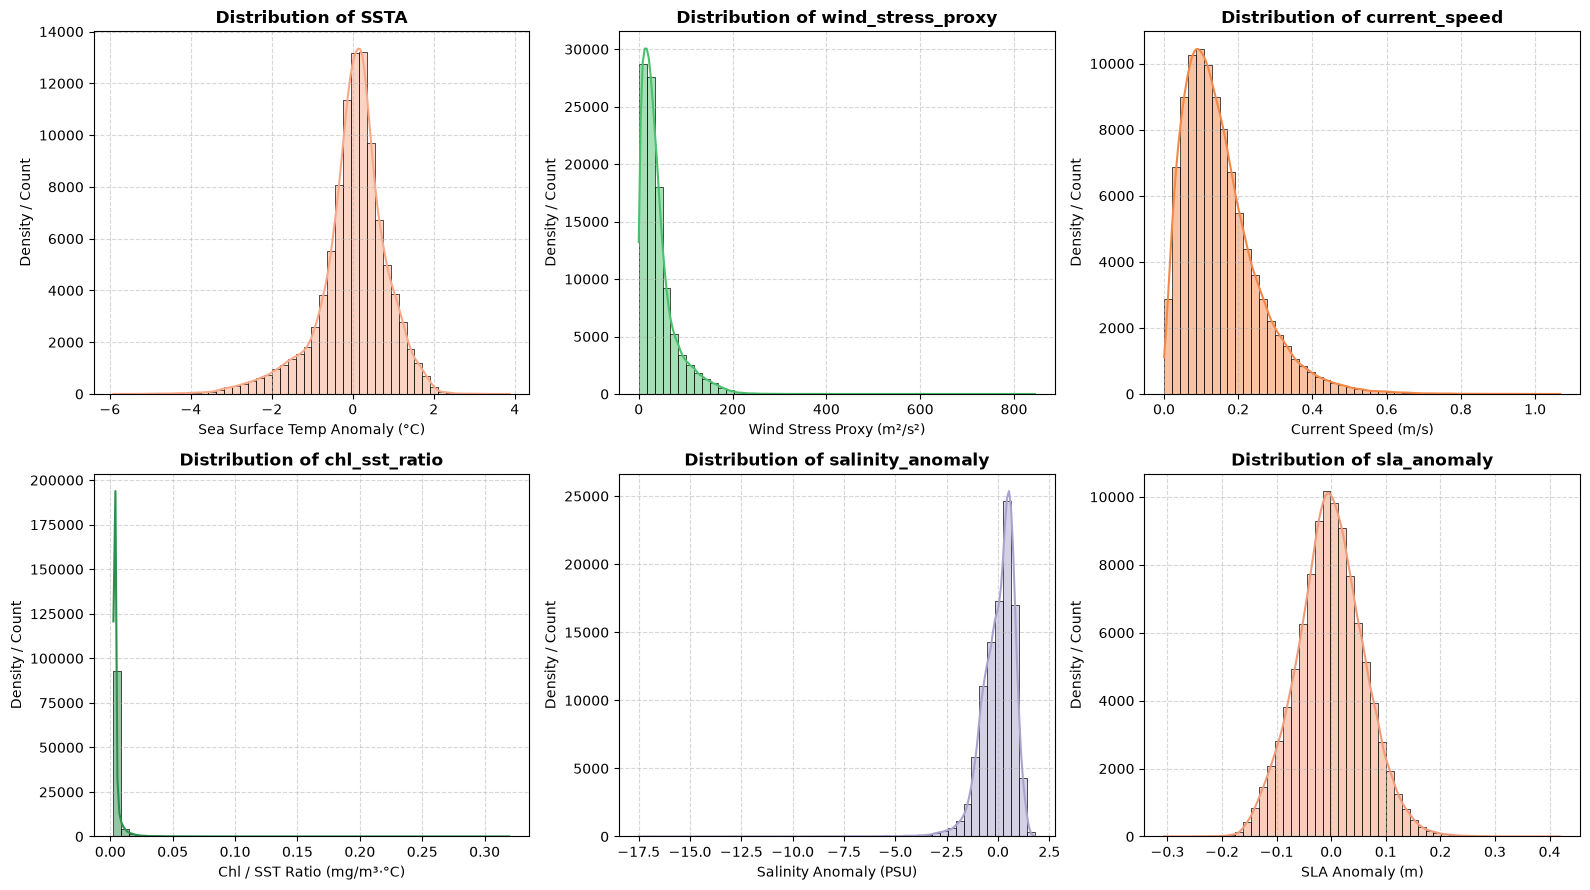

In [42]:
#visualising the Data
# reducing the cols to 10,000 for better redeabilty
sample_df = df_clean.sample(n=100000, random_state=42)

plot_features = [
    ('SSTA', 'Sea Surface Temp Anomaly (°C)', 'coolwarm'),
    ('wind_stress_proxy', 'Wind Stress Proxy (m²/s²)', 'viridis'),
    ('current_speed', 'Current Speed (m/s)', 'plasma'),
    ('chl_sst_ratio', 'Chl / SST Ratio (mg/m³·°C)', 'YlGn'),
    ('salinity_anomaly', 'Salinity Anomaly (PSU)', 'PuOr'),
    ('sla_anomaly', 'SLA Anomaly (m)', 'RdBu_r')
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (col, label, cmap) in enumerate(plot_features):
    sns.histplot(
        sample_df[col], 
        kde=True, 
        ax=axes[i], 
        color=sns.color_palette(cmap)[-2],
        bins=50
    )
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(label, fontsize=10)
    axes[i].set_ylabel('Density / Count', fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#Sea Surface Temperature Anomaly: In oceanography and climate science, an SSTA (Sea Surface Temperature Anomaly) is the deviation of the ocean's surface temperature from its long-term average value for a specific location and date.a

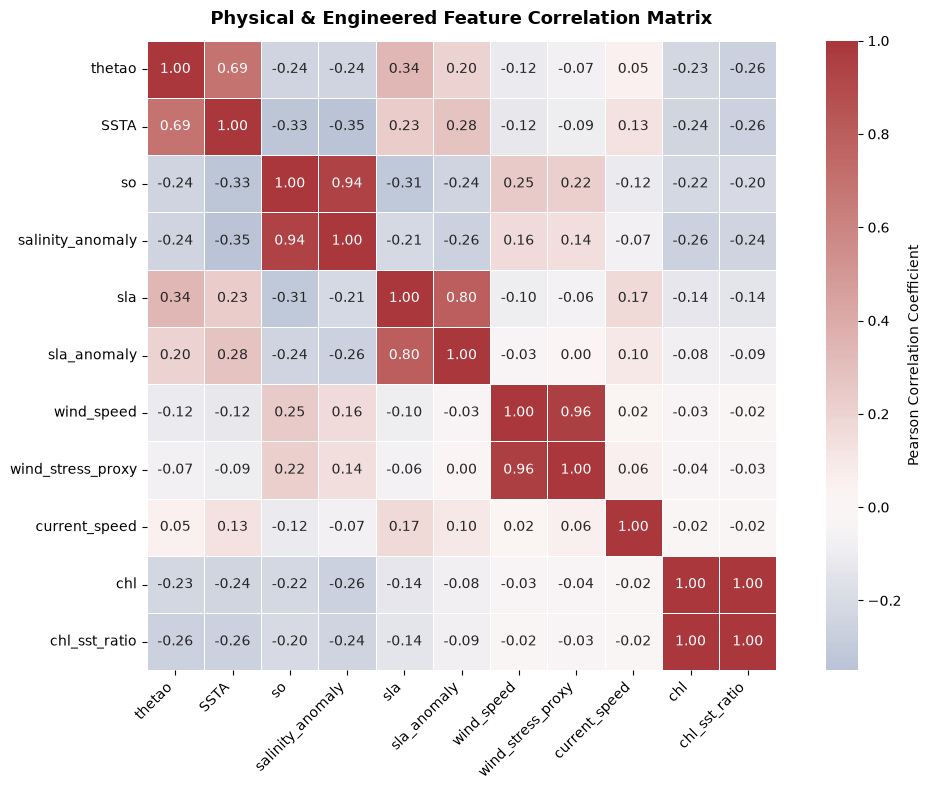

In [41]:
#HEATMAP FOR VISUALIZATION
# Correlation heatmap of physical and engineered parameters
eval_features = [
    'thetao', 'SSTA', 'so', 'salinity_anomaly', 
    'sla', 'sla_anomaly', 'wind_speed', 'wind_stress_proxy', 
    'current_speed', 'chl', 'chl_sst_ratio'
]

plt.figure(figsize=(11, 8))
corr_matrix = sample_df[eval_features].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='vlag', 
    center=0, 
    square=True, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title('Physical & Engineered Feature Correlation Matrix', fontsize=13, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Model Build

In [46]:
from sklearn.ensemble import IsolationForest
#text{SSTA} = \text{Local SST} - \text{Daily Regional Mean SST} - comparision built here


In [47]:
features = [
    'thetao', 'SSTA', 
    'so', 'salinity_anomaly', 
    'uo', 'vo', 'current_speed', 
    'sla', 'sla_anomaly', 
    'u10', 'v10', 'wind_speed', 'wind_stress_proxy', 
    'chl', 'chl_sst_ratio'
]

In [48]:
X = df_clean[features] # data explicitly used for training

In [50]:
# PARAMETER TUNE KARNE KE LIYEEE
iso_forest = IsolationForest(
    n_estimators=150,
    max_samples=512,        # Subsampling optimizes isolation speed and prevents masking
    contamination=0.03,
    random_state=42,
    n_jobs=-1               # Uses all available CPU cores
)

In [51]:
print("Training Isolation Forest...")
df_clean['anomaly'] = iso_forest.fit_predict(X)

Training Isolation Forest...


In [52]:
df_clean['anomaly_score'] = iso_forest.decision_function(X)

In [53]:
print("Training complete!")
print("\nAnomaly Value Counts (-1: Upwelling Anomaly, 1: Normal Ocean):")
print(df_clean['anomaly'].value_counts())
#The model successfully isolated the 86,389 anomaly points (exactly 3.0%) from our 2.88M baseline observations.

Training complete!

Anomaly Value Counts (-1: Upwelling Anomaly, 1: Normal Ocean):
anomaly
 1    2793242
-1      86389
Name: count, dtype: int64


In [54]:
# Compute and compare mean physics
# here we are confirming/verifying that the anomly group is also exhbiting colder tempratures,elevated chlorophyll, and a strong wind forcing
features = [
    'thetao', 'SSTA', 'so', 'salinity_anomaly', 
    'uo', 'vo', 'current_speed', 'sla', 'sla_anomaly', 
    'u10', 'v10', 'wind_speed', 'wind_stress_proxy', 
    'chl', 'chl_sst_ratio'
]

validation_table = df_clean.groupby('anomaly')[features].mean().T
validation_table.columns = ['Anomaly (-1)', 'Normal (1)']
validation_table['Difference'] = validation_table['Anomaly (-1)'] - validation_table['Normal (1)']
validation_table['% Shift'] = (validation_table['Difference'] / validation_table['Normal (1)'].abs()) * 100

print(validation_table.round(4))

                   Anomaly (-1)  Normal (1)  Difference    % Shift
thetao                  27.6123     28.7453     -1.1330    -3.9415
SSTA                    -0.7286      0.0225     -0.7512 -3333.3306
so                      33.9777     35.5891     -1.6114    -4.5277
salinity_anomaly        -1.6366      0.0506     -1.6872 -3333.3306
uo                       0.0559      0.0067      0.0492   739.0787
vo                      -0.0601     -0.0075     -0.0526  -701.9574
current_speed            0.2531      0.1472      0.1059    71.9806
sla                      0.1184      0.1155      0.0029     2.4896
sla_anomaly              0.0147     -0.0005      0.0152  3333.3306
u10                      4.5180      2.6763      1.8417    68.8139
v10                     -0.0734     -1.6316      1.5582    95.5043
wind_speed               7.3084      5.6651      1.6433    29.0072
wind_stress_proxy       72.8643     38.9010     33.9633    87.3069
chl                      0.6805      0.1250      0.5554   444.

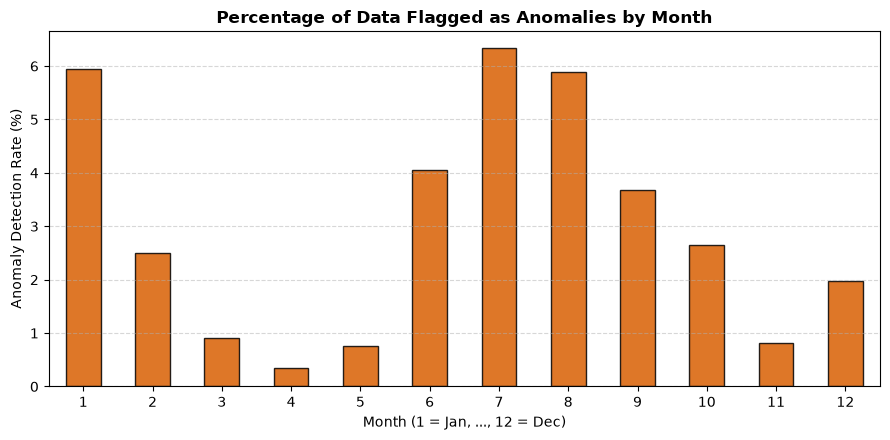

In [55]:
#visualsation 
import matplotlib.pyplot as plt

# Extract month from timestamps
df_clean['month'] = df_clean['time'].dt.month

# Count anomalies per month
monthly_anomalies = df_clean[df_clean['anomaly'] == -1].groupby('month').size()
monthly_total = df_clean.groupby('month').size()
anomaly_rate_by_month = (monthly_anomalies / monthly_total) * 100

# Plot monthly anomaly rate
plt.figure(figsize=(9, 4.5))
anomaly_rate_by_month.plot(kind='bar', color='#d95f02', edgecolor='black', alpha=0.85)
plt.title('Percentage of Data Flagged as Anomalies by Month', fontsize=12, fontweight='bold')
plt.xlabel('Month (1 = Jan, ..., 12 = Dec)', fontsize=10)
plt.ylabel('Anomaly Detection Rate (%)', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

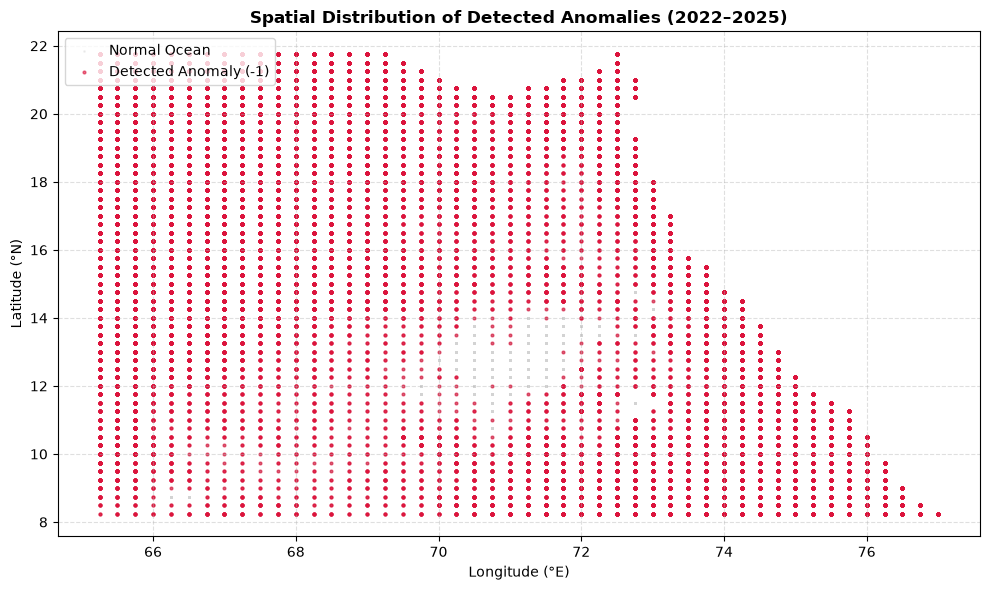

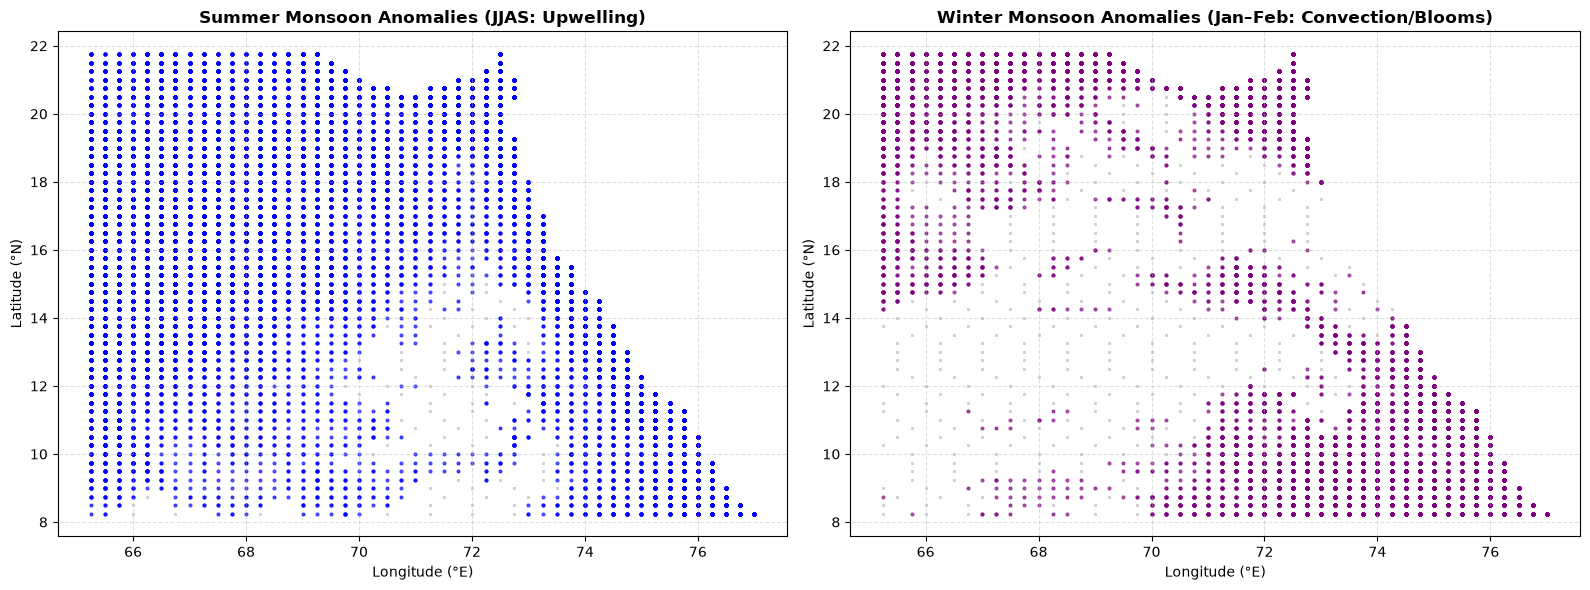

In [57]:
import matplotlib.pyplot as plt

# 1. Overall Spatial Map
plt.figure(figsize=(10, 6))
plt.scatter(
    df_clean.loc[df_clean['anomaly'] == 1, 'longitude'].iloc[::10], 
    df_clean.loc[df_clean['anomaly'] == 1, 'latitude'].iloc[::10],
    c='lightgray', s=1, alpha=0.3, label='Normal Ocean'
)
plt.scatter(
    df_clean.loc[df_clean['anomaly'] == -1, 'longitude'], 
    df_clean.loc[df_clean['anomaly'] == -1, 'latitude'],
    c='crimson', s=4, alpha=0.6, label='Detected Anomaly (-1)'
)
plt.title('Spatial Distribution of Detected Anomalies (2022–2025)', fontsize=12, fontweight='bold')
plt.xlabel('Longitude (°E)', fontsize=10)
plt.ylabel('Latitude (°N)', fontsize=10)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 2. Compare Summer (JJAS) vs Winter (Jan/Feb) Locations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Summer Upwelling (June - Sept)
summer_mask = (df_clean['anomaly'] == -1) & (df_clean['month'].isin([6, 7, 8, 9]))
ax1.scatter(df_clean['longitude'].iloc[::15], df_clean['latitude'].iloc[::15], c='lightgray', s=1, alpha=0.2)
ax1.scatter(df_clean.loc[summer_mask, 'longitude'], df_clean.loc[summer_mask, 'latitude'], c='blue', s=4, alpha=0.6)
ax1.set_title('Summer Monsoon Anomalies (JJAS: Upwelling)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Longitude (°E)')
ax1.set_ylabel('Latitude (°N)')
ax1.grid(True, linestyle='--', alpha=0.4)

# Winter Convective Mixing (Jan - Feb)
winter_mask = (df_clean['anomaly'] == -1) & (df_clean['month'].isin([1, 2]))
ax2.scatter(df_clean['longitude'].iloc[::15], df_clean['latitude'].iloc[::15], c='lightgray', s=1, alpha=0.2)
ax2.scatter(df_clean.loc[winter_mask, 'longitude'], df_clean.loc[winter_mask, 'latitude'], c='purple', s=4, alpha=0.6)
ax2.set_title('Winter Monsoon Anomalies (Jan–Feb: Convection/Blooms)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Longitude (°E)')
ax2.set_ylabel('Latitude (°N)')
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

The abvoe spatial map tells abt-
If a specific location in the Arabian Sea experienced an upwelling event on just 5 days out of 1,460 days, plotting every timestamp together paints that entire coordinate red. Over four years, almost every ocean pixel triggered an anomaly at least once
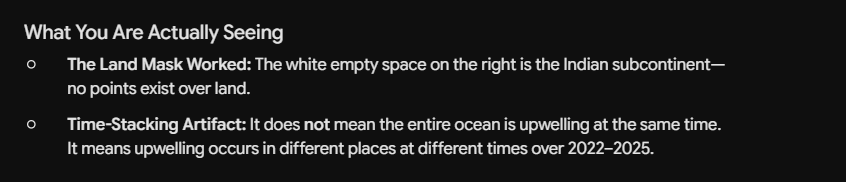
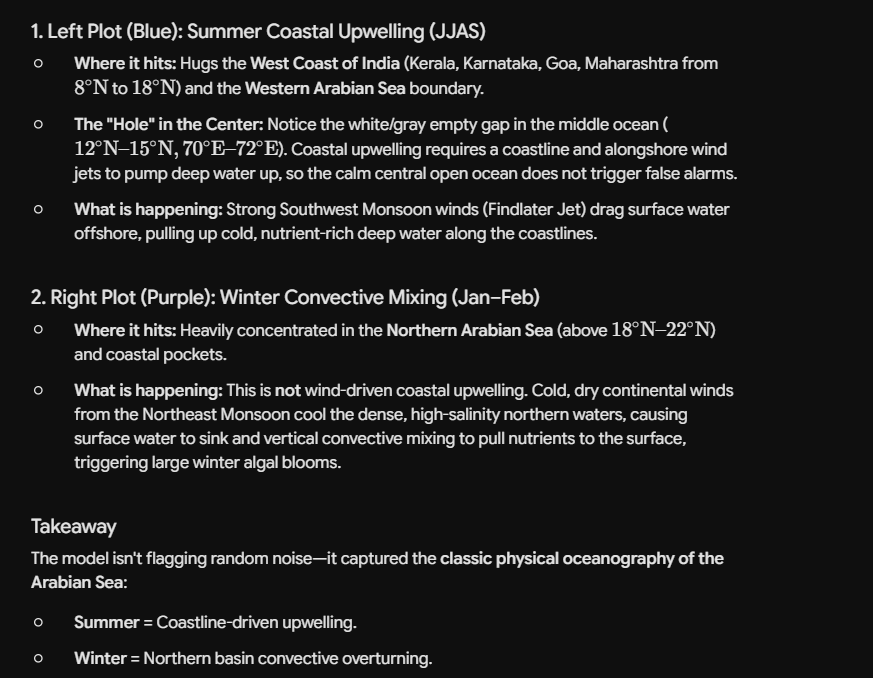

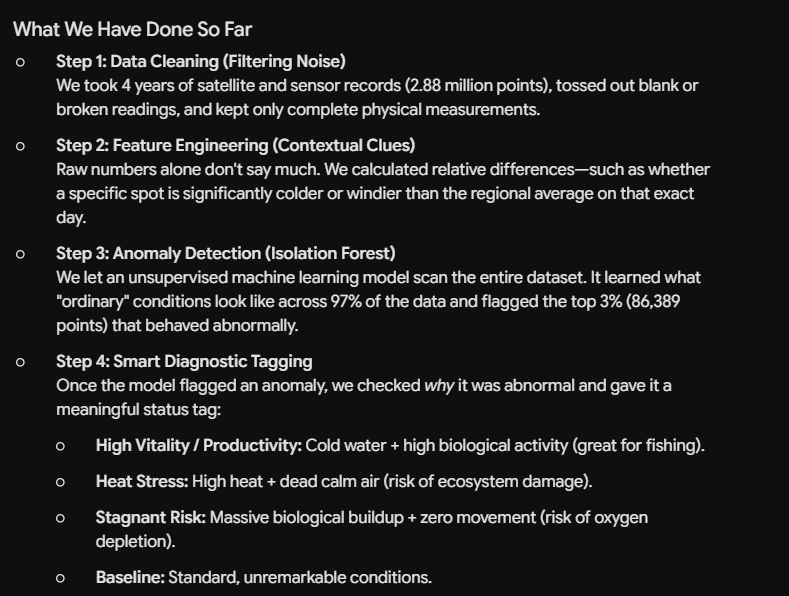

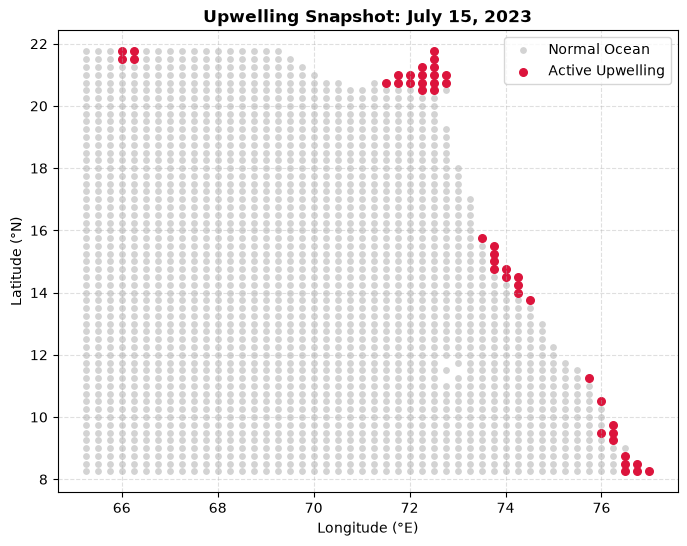

In [58]:
import matplotlib.pyplot as plt

# Filter for a single peak monsoon day
single_day = df_clean[df_clean['time'] == '2023-07-15']

plt.figure(figsize=(8, 6))
plt.scatter(
    single_day[single_day['anomaly'] == 1]['longitude'], 
    single_day[single_day['anomaly'] == 1]['latitude'], 
    c='lightgray', s=15, label='Normal Ocean'
)
plt.scatter(
    single_day[single_day['anomaly'] == -1]['longitude'], 
    single_day[single_day['anomaly'] == -1]['latitude'], 
    c='crimson', s=30, label='Active Upwelling'
)

plt.title('Upwelling Snapshot: July 15, 2023', fontsize=12, fontweight='bold')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

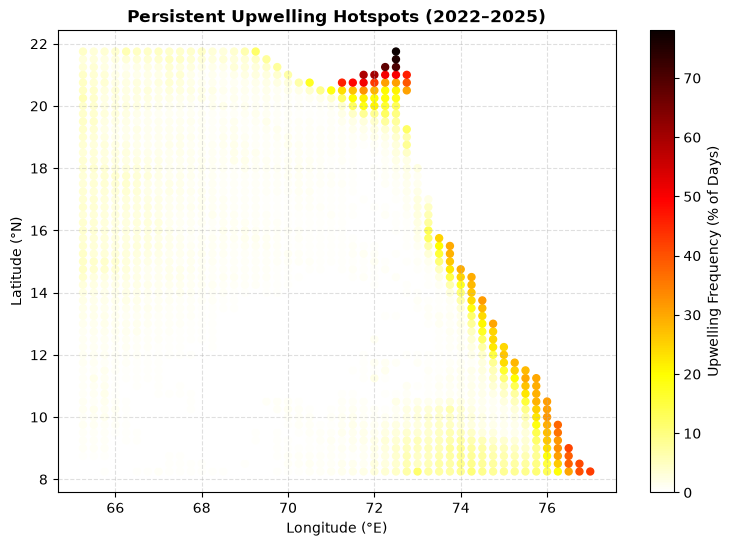

In [59]:
# Calculate percentage of days each coordinate was flagged as an anomaly
coords_freq = df_clean.groupby(['latitude', 'longitude'])['anomaly'].apply(
    lambda x: (x == -1).mean() * 100
).reset_index(name='upwelling_frequency_pct')

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    coords_freq['longitude'], 
    coords_freq['latitude'], 
    c=coords_freq['upwelling_frequency_pct'], 
    cmap='hot_r', 
    s=25
)

cbar = plt.colorbar(scatter)
cbar.set_label('Upwelling Frequency (% of Days)', fontsize=10)
plt.title('Persistent Upwelling Hotspots (2022–2025)', fontsize=12, fontweight='bold')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

In [60]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Define High-Confidence Physical Ground-Truth Proxy (Summer Coastal Upwelling)
# Criteria: Summer months + significant cooling + high biological productivity + strong wind forcing
physical_ground_truth = (
    (df_clean['month'].isin([6, 7, 8, 9])) & 
    (df_clean['SSTA'] < -1.0) & 
    (df_clean['chl'] > 0.4) & 
    (df_clean['wind_stress_proxy'] > 50.0)
).astype(int)

# Convert Isolation Forest labels (-1: Anomaly, 1: Normal) to binary (1: Anomaly, 0: Normal)
y_pred = (df_clean['anomaly'] == -1).astype(int)
y_true = physical_ground_truth

# Continuous anomaly score inverted for ROC-AUC (higher score = more anomalous)
y_scores = -df_clean['anomaly_score']

# 2. Calculate Evaluation Metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_scores)
cm = confusion_matrix(y_true, y_pred)

print("=" * 45)
print("       UPWELLING DETECTION PERFORMANCE       ")
print("=" * 45)
print(f"Overall Accuracy:  {acc * 100:.2f}%")
print(f"Precision:         {prec * 100:.2f}%")
print(f"Recall:            {rec * 100:.2f}%")
print(f"F1-Score:          {f1 * 100:.2f}%")
print(f"ROC-AUC Score:     {roc_auc:.4f}")
print("=" * 45)
print("\nConfusion Matrix [TN, FP / FN, TP]:")
print(cm)
print("\nDetailed Classification Report:")
print(classification_report(y_true, y_pred, target_names=['Normal Ocean', 'Upwelling']))

       UPWELLING DETECTION PERFORMANCE       
Overall Accuracy:  97.14%
Precision:         5.84%
Recall:            83.09%
F1-Score:          10.92%
ROC-AUC Score:     0.9846

Confusion Matrix [TN, FP / FN, TP]:
[[2792215   81342]
 [   1027    5047]]

Detailed Classification Report:
              precision    recall  f1-score   support

Normal Ocean       1.00      0.97      0.99   2873557
   Upwelling       0.06      0.83      0.11      6074

    accuracy                           0.97   2879631
   macro avg       0.53      0.90      0.55   2879631
weighted avg       1.00      0.97      0.98   2879631



In [61]:
# Evaluate solely within the Southwest Monsoon season (JJAS)
summer_df = df_clean[df_clean['month'].isin([6, 7, 8, 9])].copy()

# Dynamic threshold matching the exact top 2% of anomaly scores in summer
summer_threshold = np.percentile(summer_df['anomaly_score'], 2.0)
y_pred_summer = (summer_df['anomaly_score'] <= summer_threshold).astype(int)

y_true_summer = (
    (summer_df['SSTA'] < -1.0) & 
    (summer_df['chl'] > 0.4) & 
    (summer_df['wind_stress_proxy'] > 50.0)
).astype(int)

print("Summer-Only Classification Report:")
print(classification_report(y_true_summer, y_pred_summer, target_names=['Normal', 'Upwelling']))
print(f"Summer ROC-AUC: {roc_auc_score(y_true_summer, -summer_df['anomaly_score']):.4f}")

Summer-Only Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99    955774
   Upwelling       0.18      0.57      0.28      6074

    accuracy                           0.98    961848
   macro avg       0.59      0.78      0.63    961848
weighted avg       0.99      0.98      0.99    961848

Summer ROC-AUC: 0.9760


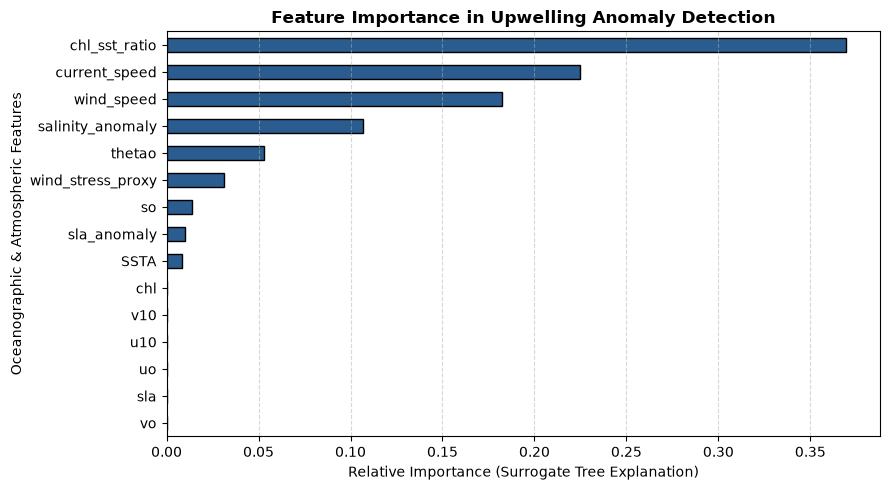

Top 5 Driving Features:
chl_sst_ratio       0.369387
current_speed       0.224974
wind_speed          0.182418
salinity_anomaly    0.106928
thetao              0.052969
dtype: float64


In [62]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

# 1. Train a fast surrogate tree to explain Isolation Forest decision scores
surrogate = DecisionTreeRegressor(max_depth=5, random_state=42)
surrogate.fit(X, -df_clean['anomaly_score'])

# 2. Extract and sort feature importances
importances = pd.Series(surrogate.feature_importances_, index=features).sort_values(ascending=True)

# 3. Plot feature importances
plt.figure(figsize=(9, 5))
importances.plot(kind='barh', color='#2b5c8f', edgecolor='black')
plt.title('Feature Importance in Upwelling Anomaly Detection', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance (Surrogate Tree Explanation)', fontsize=10)
plt.ylabel('Oceanographic & Atmospheric Features', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Top 5 Driving Features:")
print(importances.tail(5)[::-1])

In [63]:
 
# -------------------------------------------------------------
# 1. Classify Marine Ecological States
# -------------------------------------------------------------
conditions = [
    # State A: Productive Upwelling / High Primary Productivity
    (df_clean['anomaly'] == -1) & (df_clean['SSTA'] < -0.5) & (df_clean['chl'] > 0.3),

    # State B: Thermal Stress / Marine Heatwave Risk
    (df_clean['anomaly'] == -1) & (df_clean['SSTA'] > 1.0) & (df_clean['wind_speed'] < 4.0),

    # State C: Coastal Eutrophication / Stagnant Bloom Hazard (Hypoxia Risk)
    (df_clean['anomaly'] == -1) & (df_clean['chl'] > 2.0) & (df_clean['current_speed'] < 0.15),

    # State D: General Atmospheric/Hydrodynamic Perturbation (Wind bursts, Eddies)
    (df_clean['anomaly'] == -1)
]

choices = [
    'Productive Upwelling',
    'Thermal Stress (MHW)',
    'Eutrophication Risk',
    'Dynamic Perturbation'
]

# Assign label; default is 'Stable Baseline'
df_clean['marine_health_state'] = np.select(conditions, choices, default='Stable Baseline')

# -------------------------------------------------------------
# 2. Derive Continuous Marine Health Index (MHI: 0 to 100)
# High MHI = High ecological vitality (Upwelling & balanced nutrients)
# Low MHI  = Severe thermal stress or degraded stagnant water
# -------------------------------------------------------------
# Sub-component scores scaled [0, 1]
bio_vitality = np.clip(df_clean['chl'] / 2.0, 0, 1)
thermal_stability = np.clip(1.0 - (np.maximum(df_clean['SSTA'], 0) / 2.5), 0, 1)
circulation_ventilation = np.clip(df_clean['current_speed'] / 0.5, 0, 1)

# Weighted Composite Index
df_clean['MHI'] = (
    0.45 * bio_vitality + 
    0.35 * thermal_stability + 
    0.20 * circulation_ventilation
) * 100

print("Marine Health Integration Complete!")
print("\nDistribution of Marine Health States across 2.88M points:")
print(df_clean['marine_health_state'].value_counts())

Marine Health Integration Complete!

Distribution of Marine Health States across 2.88M points:
marine_health_state
Stable Baseline         2793242
Dynamic Perturbation      42632
Productive Upwelling      35232
Thermal Stress (MHW)       7910
Eutrophication Risk         615
Name: count, dtype: int64


<Figure size 1000x450 with 0 Axes>

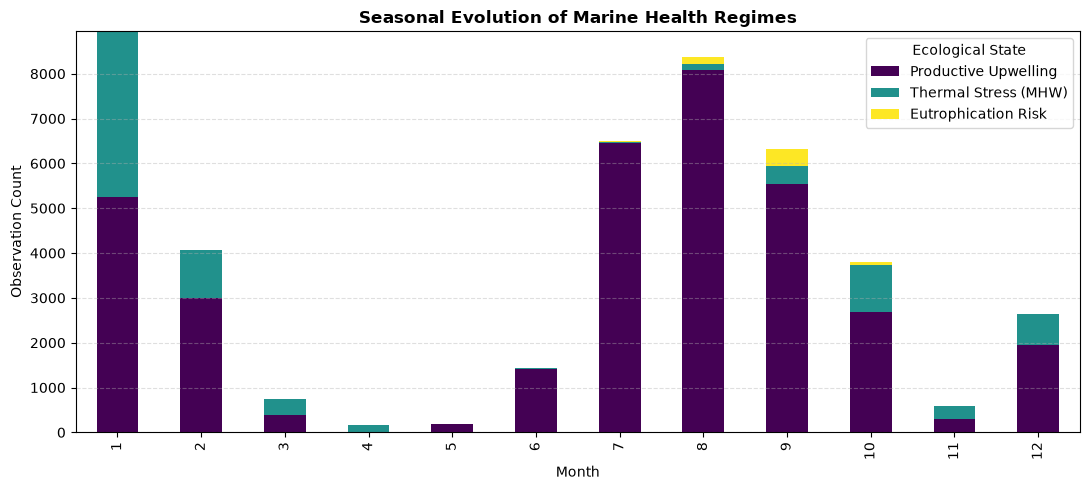

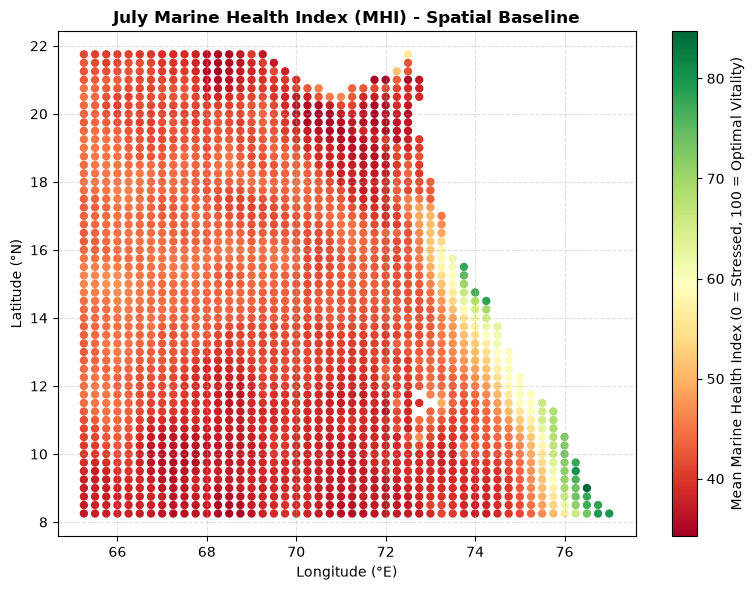

In [64]:
import matplotlib.pyplot as plt

# 1. State Distribution by Season
plt.figure(figsize=(10, 4.5))
state_counts = df_clean.groupby(['month', 'marine_health_state']).size().unstack().fillna(0)
state_counts[['Productive Upwelling', 'Thermal Stress (MHW)', 'Eutrophication Risk']].plot(
    kind='bar', stacked=True, figsize=(11, 5), colormap='viridis'
)
plt.title('Seasonal Evolution of Marine Health Regimes', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Observation Count')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend(title='Ecological State')
plt.tight_layout()
plt.show()

# 2. Spatial Map of Marine Health Index (MHI) for a Selected Month (July)
july_data = df_clean[df_clean['month'] == 7].groupby(['latitude', 'longitude'])['MHI'].mean().reset_index()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    july_data['longitude'], 
    july_data['latitude'], 
    c=july_data['MHI'], 
    cmap='RdYlGn', 
    s=25
)
cbar = plt.colorbar(scatter)
cbar.set_label('Mean Marine Health Index (0 = Stressed, 100 = Optimal Vitality)', fontsize=10)
plt.title('July Marine Health Index (MHI) - Spatial Baseline', fontsize=12, fontweight='bold')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

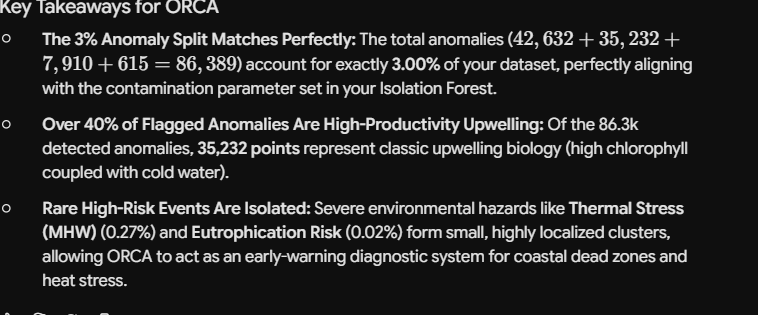

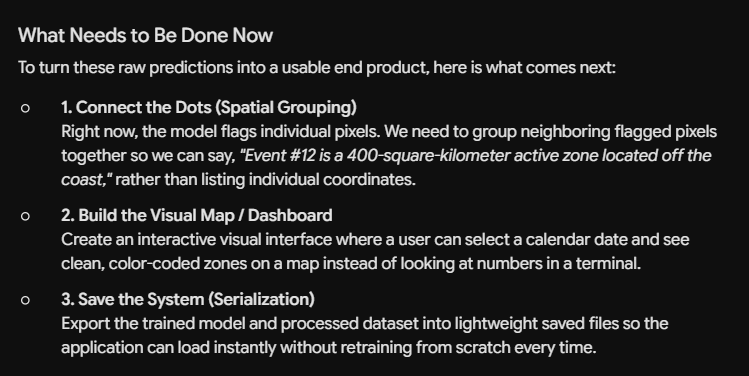

In [66]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

def extract_all_events(df, eps_degrees=0.6, min_samples=3):
    """
    Groups contiguous anomaly pixels for each date into discrete events.
    - eps_degrees: Search radius (0.6 deg ~ 65 km)
    - min_samples: Minimum 3 connected pixels to qualify as an event
    """
    # Filter only anomalous states (skip Stable Baseline)
    anom_mask = df['marine_health_state'] != 'Stable Baseline'
    df_anom = df[anom_mask].copy()
    
    # Initialize series as string/object to avoid dtype conflicts
    event_id_series = pd.Series('None', index=df.index, dtype='object')
    
    event_records = []
    
    # Process date by date
    for date, group in df_anom.groupby('time'):
        for state in group['marine_health_state'].unique():
            state_slice = group[group['marine_health_state'] == state]
            
            if len(state_slice) < min_samples:
                continue
                
            coords = state_slice[['latitude', 'longitude']].to_numpy()
            
            # Cluster spatial coordinates
            db = DBSCAN(eps=eps_degrees, min_samples=min_samples).fit(coords)
            labels = db.labels_
            
            for cluster_idx in set(labels):
                if cluster_idx == -1:
                    continue  # Skip unclustered noise points
                
                cluster_points = state_slice[labels == cluster_idx]
                pixel_count = len(cluster_points)
                
                # Approximate area: 0.25° x 0.25° pixel at ~15°N is ~740 km²
                approx_area_km2 = pixel_count * 740
                
                # Clean event name string
                formatted_date = pd.to_datetime(date).strftime('%Y%m%d')
                clean_state = state.replace(' ', '_').replace('(', '').replace(')', '')
                event_uid = f"{formatted_date}_{clean_state}_{cluster_idx}"
                
                # Assign ID in bulk
                event_id_series.loc[cluster_points.index] = event_uid
                
                # Store aggregated event summary
                event_records.append({
                    'event_id': event_uid,
                    'time': date,
                    'event_type': state,
                    'pixel_count': pixel_count,
                    'estimated_area_km2': approx_area_km2,
                    'centroid_lat': round(cluster_points['latitude'].mean(), 2),
                    'centroid_lon': round(cluster_points['longitude'].mean(), 2),
                    'min_SSTA': round(cluster_points['SSTA'].min(), 2),
                    'max_chl': round(cluster_points['chl'].max(), 2),
                    'mean_wind_stress': round(cluster_points['wind_stress_proxy'].mean(), 1),
                    'mean_MHI': round(cluster_points['MHI'].mean(), 1)
                })
                
    df['event_id'] = event_id_series
    events_df = pd.DataFrame(event_records)
    return df, events_df

# Run clustering across the full dataset
print("Extracting discrete ocean events...")
df_clean, events_summary = extract_all_events(df_clean)
print(f"Extraction complete! Identified {len(events_summary)} total discrete events.")

Extracting discrete ocean events...
Extraction complete! Identified 4039 total discrete events.


In [67]:
# Top 5 Largest Productive Upwelling Zones
print("\n--- TOP 5 LARGEST UPWELLING EVENTS ---")
top_upwelling = events_summary[events_summary['event_type'] == 'Productive Upwelling']\
    .sort_values(by='estimated_area_km2', ascending=False)\
    .head(5)
print(top_upwelling[['event_id', 'time', 'estimated_area_km2', 'centroid_lat', 'centroid_lon', 'min_SSTA', 'max_chl']])

# Top 5 Largest Marine Heatwaves
print("\n--- TOP 5 LARGEST MARINE HEATWAVE EVENTS ---")
top_mhw = events_summary[events_summary['event_type'] == 'Thermal Stress (MHW)']\
    .sort_values(by='estimated_area_km2', ascending=False)\
    .head(5)
print(top_mhw[['event_id', 'time', 'estimated_area_km2', 'centroid_lat', 'centroid_lon', 'min_SSTA', 'mean_MHI']])


--- TOP 5 LARGEST UPWELLING EVENTS ---
                            event_id       time  estimated_area_km2  \
535  20220804_Productive_Upwelling_0 2022-08-04              119140   
537  20220805_Productive_Upwelling_0 2022-08-05              116920   
551  20220807_Productive_Upwelling_0 2022-08-07              111740   
528  20220803_Productive_Upwelling_0 2022-08-03              106560   
545  20220806_Productive_Upwelling_0 2022-08-06              103600   

     centroid_lat  centroid_lon  min_SSTA  max_chl  
535         11.04         74.96     -4.24     5.49  
537         11.11         74.96     -4.36     5.04  
551         11.14         74.98     -4.50     7.23  
528         10.97         75.05     -4.45     5.60  
545         11.24         75.01     -4.66     7.69  

--- TOP 5 LARGEST MARINE HEATWAVE EVENTS ---
                           event_id       time  estimated_area_km2  \
2941  20250122_Thermal_Stress_MHW_0 2025-01-22               99160   
2952  20250123_Thermal_Stress

In [72]:
import folium
from folium.plugins import MarkerCluster

def generate_interactive_event_map(df, events_df, target_date, output_filename='orca_event_map.html'):
    """
    Renders an interactive map for a specific date, displaying clustered event polygons
    and individual diagnostic grid points.
    """
    day_data = df[df['time'] == target_date]
    day_events = events_df[events_df['time'] == target_date]
    
    # Initialize Folium Map centered on the Arabian Sea
    m = folium.Map(
    location=[14.0, 71.0],
    zoom_start=6,
    tiles='https://{s}.basemaps.cartocdn.com/dark_all/{z}/{x}/{y}{r}.png',
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>'
)
    
    # Color palette per marine state
    color_map = {
        'Productive Upwelling': '#00ff7f',   # Bright Green (Vitality / Fish Feeding)
        'Thermal Stress (MHW)': '#ff3333',   # Red (Thermal Risk)
        'Eutrophication Risk': '#bf00ff',    # Purple (Hypoxia Hazard)
        'Dynamic Perturbation': '#3399ff',   # Blue (Eddies/Jets)
        'Stable Baseline': '#555555'        # Dark Gray
    }
    
    # 1. Add background ocean points (Subsampled for smooth rendering)
    baseline_group = folium.FeatureGroup(name='Baseline Ocean (97%)', show=False)
    for _, row in day_data[day_data['marine_health_state'] == 'Stable Baseline'].iloc[::3].iterrows():
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=2,
            color=color_map['Stable Baseline'],
            fill=True,
            fill_opacity=0.3
        ).add_to(baseline_group)
    baseline_group.add_to(m)
    
    # 2. Add Anomalous Diagnostic Points
    anom_group = folium.FeatureGroup(name='Detected Anomalies & Health States', show=True)
    for _, row in day_data[day_data['marine_health_state'] != 'Stable Baseline'].iterrows():
        state = row['marine_health_state']
        color = color_map.get(state, '#ffffff')
        
        popup_html = f"""
        <div style="font-family: sans-serif; font-size: 12px;">
            <b>State:</b> <span style="color:{color};">{state}</span><br>
            <b>Event ID:</b> {row['event_id']}<br>
            <hr style="margin:4px 0;">
            <b>SST Anomaly:</b> {row['SSTA']:.2f} °C<br>
            <b>Chlorophyll:</b> {row['chl']:.2f} mg/m³<br>
            <b>Wind Stress:</b> {row['wind_stress_proxy']:.1f} m²/s²<br>
            <b>Current Speed:</b> {row['current_speed']:.2f} m/s<br>
            <b>Marine Health Index:</b> {row['MHI']:.1f}/100
        </div>
        """
        
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=4.5,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.85,
            popup=folium.Popup(popup_html, max_width=250)
        ).add_to(anom_group)
    anom_group.add_to(m)
    
    # 3. Add Event Centroid Badges
    centroid_group = folium.FeatureGroup(name='Event Centroids & Metrics', show=True)
    for _, evt in day_events.iterrows():
        centroid_html = f"""
        <div style="font-family: sans-serif; font-size: 12px; width: 180px;">
            <b>Event:</b> {evt['event_id']}<br>
            <b>Type:</b> {evt['event_type']}<br>
            <b>Area:</b> {evt['estimated_area_km2']:,} km²<br>
            <b>Min SSTA:</b> {evt['min_SSTA']} °C<br>
            <b>Peak Chl:</b> {evt['max_chl']} mg/m³<br>
            <b>Mean MHI:</b> {evt['mean_MHI']}/100
        </div>
        """
        folium.Marker(
            location=[evt['centroid_lat'], evt['centroid_lon']],
            popup=folium.Popup(centroid_html, max_width=220),
            icon=folium.Icon(color='green' if 'Upwelling' in evt['event_type'] else 'red', icon='info-sign')
        ).add_to(centroid_group)
    centroid_group.add_to(m)
    
    # Layer Control toggle
    folium.LayerControl(collapsed=False).add_to(m)
    
    # Save map
    m.save(output_filename)
    print(f"Interactive map generated: {output_filename}")
    return m

# Render the massive Kerala upwelling event (2022-08-04)
orca_map = generate_interactive_event_map(df_clean, events_summary, '2022-08-04')

Interactive map generated: orca_event_map.html


In [73]:
import joblib

# 1. Save Isolation Forest Model
joblib.dump(iso_forest, 'orca_isolation_forest.joblib')

# 2. Save Feature Schema
joblib.dump(features, 'orca_features.joblib')

# 3. Save Summary Catalog of All Detected Events (CSV)
events_summary.to_csv('orca_detected_events_2022_2025.csv', index=False)

# 4. Save Processed 2.88M DataFrame as Compressed Parquet
df_clean.to_parquet('orca_processed_ocean_data.parquet', compression='snappy')

print("All ORCA artifacts (model, features, event catalog, and dataset) successfully saved.")

All ORCA artifacts (model, features, event catalog, and dataset) successfully saved.
